<a href="https://colab.research.google.com/github/dkalchenko01/UA-Locations-NER-Deep-Learning/blob/eda-%26-validation/notebooks/01_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EDA and Metric Analysis

- Perform Exploratory Data Analysis (EDA).
- Analyze the proposed target metric: discuss its strengths, weaknesses, and potential edge cases.
- Suggest complementary metrics to capture other aspects of performance.
- Propose an alternative target metric, with justification.

# Environment Setup

In [52]:
import os
import sys
import ast
import base64
import random
import subprocess

from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow.parquet as pq

In [ ]:
if "google.colab" in sys.modules:
    from google.colab import userdata
    token = userdata.get("GITHUB_TOKEN")
    root = "/content"
else:
    from kaggle_secrets import UserSecretsClient
    token = UserSecretsClient().get_secret("GITHUB_TOKEN")
    root = "/kaggle/working"

repo = "UA-Locations-NER-Deep-Learning"
branch = "eda-&-validation"
repo_dir = f"{root}/{repo}"

auth = base64.b64encode(f"x-access-token:{token}".encode()).decode()
env = os.environ.copy()
env["GIT_CONFIG_COUNT"] = "1"
env["GIT_CONFIG_KEY_0"] = "http.extraheader"
env["GIT_CONFIG_VALUE_0"] = f"AUTHORIZATION: basic {auth}"

if not os.path.exists(repo_dir):
    subprocess.run(
        ["git", "clone", "-b", branch, f"https://github.com/dkalchenko01/{repo}.git", repo_dir],
        env=env, check=True
    )

print("Repository:", repo_dir)

Repository: /content/UA-Locations-NER-Deep-Learning


In [ ]:
from src.data_io import get_data_dir
sys.path.insert(0, repo_dir)

ENVIRONMENT = "colab" if root == "/content" else "kaggle"

data_dir = Path(get_data_dir(ENVIRONMENT))
print("Data directory:", data_dir)

for path in sorted(data_dir.iterdir()):
    print(path.name, "DIR" if path.is_dir() else "FILE")

100%|██████████| 811M/811M [00:11<00:00, 73.5MB/s]

Extracting files...


Data directory: /root/.cache/kagglehub/competitions/kse-ua-location-extraction-2026


# Dataset Overview

##  Dataset Schema

In [ ]:
for file in sorted(data_dir.glob("*.csv")):
    print(f"{file.name}")
    print("Columns:", pd.read_csv(file, nrows=0).columns.tolist(), "\n")

file = data_dir / "uk_geo_dataset_processed_v1.parquet"
print(f"{file.name}")
print(pq.ParquetFile(file).schema_arrow, "\n")

labeling_sample.csv
Columns: ['text', 'locations', 'loc_markers'] 

ru_geo_dataset.csv
Columns: ['text', 'loc_markers', 'org_markers', 'per_markers', 'doc_id', 'sent_id'] 

test.csv
Columns: ['text_id', 'text', 'locations'] 

uk_geo_dataset.csv
Columns: ['text', 'loc_markers', 'org_markers', 'per_markers', 'is_valid'] 

uk_geo_dataset_processed_v1.parquet
tokens: extension<arrow.json>
labels: extension<arrow.json>
is_valid: int64
-- schema metadata --
pandas: '{"column_indexes": [{"field_name": null, "metadata": null, "name' + 618 



The Ukrainian and Russian CSV files contain labeled location spans, but have different additional columns. `labeling_sample.csv` provides annotation examples, while `test.csv` is used for Kaggle predictions. The processed Parquet file requires further verification.

In [ ]:
for name in ["labeling_sample.csv", "uk_geo_dataset.csv", "ru_geo_dataset.csv", "test.csv"]:
    print(f"\n{name}")
    display(pd.read_csv(data_dir / name, nrows=2).T)

print("\nuk_geo_dataset_processed_v1.parquet")
parquet = pq.ParquetFile(data_dir / "uk_geo_dataset_processed_v1.parquet")
display(next(parquet.iter_batches(batch_size=2)).to_pandas().T)


labeling_sample.csv


,0,1
text,-261.310,"Проспект Бандери стоїть, як і пів міста… довго..."
locations,[],['Проспект Бандери']
loc_markers,[],"[(0, 16)]"



uk_geo_dataset.csv


,0,1
text,"Чим довше мають скачки тиску гіпертензією, тим...","А поки що починали цвісти троянди, випускники ..."
loc_markers,[],[]
org_markers,[],[]
per_markers,[],"[(114, 131)]"
is_valid,0,0



ru_geo_dataset.csv


,0,1
text,Вице-премьер по социальным вопросам Татьяна Го...,"По словам Голиковой, чаще всего онкологические..."
loc_markers,"[(82, 88)]","[(89, 98), (100, 108), (110, 118), (121, 139),..."
org_markers,"[(149, 160)]",[]
per_markers,"[(36, 52)]","[(10, 19)]"
doc_id,0,0
sent_id,0,1



test.csv


,0,1
text_id,0,1
text,"❗️Кількість поранених зросла до трьох, – Кличк...","🥤В Києві за 91,13 млн гривень починаються робо..."
locations,[],[]



uk_geo_dataset_processed_v1.parquet


,0,1
tokens,"[""\u0427\u0438\u043c"",""\u0434\u043e\u0432\u044...","[""\u0410"",""\u043f\u043e\u043a\u0438"",""\u0449\u..."
labels,"[""O"",""O"",""O"",""O"",""O"",""O"",""O"",""O"",""O"",""O"",""O"",""...","[""O"",""O"",""O"",""O"",""O"",""O"",""O"",""O"",""O"",""O"",""O"",""..."
is_valid,0,0


In [ ]:
df = pd.read_csv(data_dir / "ru_geo_dataset.csv", nrows=2)
text = df.loc[0, "text"]
markers = ast.literal_eval(df.loc[0, "loc_markers"])

print("TEXT:", text)
print("\nLOCATIONS:", [text[start:end] for start, end in markers])
print("MARKERS:", markers)

TEXT: Вице-премьер по социальным вопросам Татьяна Голикова рассказала, в каких регионах России зафиксирована наиболее высокая смертность от рака, сообщает РИА Новости.

LOCATIONS: ['России']
MARKERS: [(82, 88)]


In [ ]:
for chunk in pd.read_csv(data_dir / "uk_geo_dataset.csv", chunksize=1000):
    rows = chunk[chunk["loc_markers"].fillna("[]") != "[]"]
    if not rows.empty:
        row = rows.iloc[0]
        break

text = row["text"]
markers = ast.literal_eval(row["loc_markers"])

print("TEXT:", text)
print("\nLOCATIONS:", [text[start:end] for start, end in markers])
print("MARKERS:", markers)
print("IS_VALID:", row["is_valid"])

TEXT: Подібні розіграші проводили в Великій Британії.

LOCATIONS: ['Великій Британії']
MARKERS: [(30, 46)]
IS_VALID: 0


Location annotations use character offsets `[start, end)`. This format works consistently in the inspected Ukrainian and russian examples. The `is_valid` column indicates the original validation split, not annotation quality.

## Dataset Size and Location Coverage

In [ ]:
results = []

for name in ["uk_geo_dataset.csv", "ru_geo_dataset.csv"]:
    total = 0
    with_locations = 0

    for chunk in pd.read_csv(data_dir / name, usecols=["loc_markers"], chunksize=100_000):
        total += len(chunk)
        with_locations += chunk["loc_markers"].fillna("[]").str.strip().ne("[]").sum()

    results.append({
        "dataset": name,
        "total_texts": total,
        "with_locations": with_locations,
        "without_locations": total - with_locations,
        "location_pct": round(with_locations / total * 100, 2)
    })

display(pd.DataFrame(results))

,dataset,total_texts,with_locations,without_locations,location_pct
0,uk_geo_dataset.csv,1010000,233421,776579,23.11
1,ru_geo_dataset.csv,8028840,2464436,5564404,30.69


The russian dataset is almost 8 times larger than the Ukrainian one. Locations are annotated in 30.69% of russian texts and 23.11% of Ukrainian texts. Most texts in both datasets have no annotated locations.

## Text Length Distribution

Using a random sample of 50,000 texts from each dataset

In [ ]:
lengths = {}

for name, label in [("uk_geo_dataset.csv", "UK"), ("ru_geo_dataset.csv", "RU")]:
    samples = []
    rng = np.random.default_rng(42)
    seen = 0

    for chunk in pd.read_csv(data_dir / name, usecols=["text"], chunksize=100_000):
        values = chunk["text"].dropna().str.len().to_numpy()

        for length in values:
            seen += 1
            if len(samples) < 50_000:
                samples.append(length)
            else:
                j = rng.integers(seen)
                if j < 50_000:
                    samples[j] = length

    lengths[label] = pd.Series(samples)

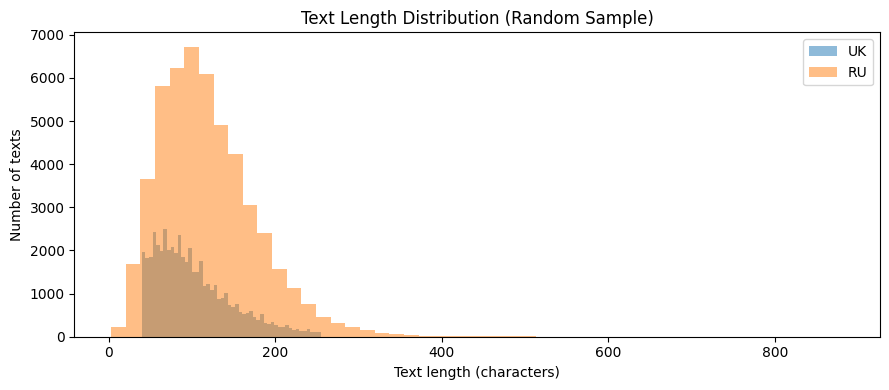

,median,p95,p99,max
UK,92.0,197.0,238.0,255.0
RU,110.0,227.0,301.0,882.0


In [ ]:
fig, ax = plt.subplots(figsize=(9, 4))

for label, values in lengths.items():
    ax.hist(values, bins=50, alpha=0.5, label=label)

ax.set_title("Text Length Distribution (Random Sample)")
ax.set_xlabel("Text length (characters)")
ax.set_ylabel("Number of texts")
ax.legend()

plt.tight_layout()
plt.show()

display(pd.DataFrame({
    label: {
        "median": values.median(),
        "p95": values.quantile(0.95),
        "p99": values.quantile(0.99),
        "max": values.max()
    }
    for label, values in lengths.items()
}).T.round(1))

Most texts are short. In random samples of 50,000 texts, the median length is 92 characters for Ukrainian and 110 for russian. russian texts tend to be longer. The Ukrainian dataset may have a 255-character limit.

In [ ]:
total = 0
at_255 = 0
over_255 = 0
max_length = 0

for chunk in pd.read_csv(data_dir / "uk_geo_dataset.csv", usecols=["text"], chunksize=100_000):
    sizes = chunk["text"].dropna().str.len()
    total += len(sizes)
    at_255 += (sizes == 255).sum()
    over_255 += (sizes > 255).sum()
    max_length = max(max_length, sizes.max())

print("Texts checked:", total)
print("Maximum length:", max_length)
print("Exactly 255 characters:", at_255)
print("Longer than 255:", over_255)

Texts checked: 1010000
Maximum length: 255
Exactly 255 characters: 519
Longer than 255: 0


All 1,010,000 Ukrainian texts are at most 255 characters long. Only 519 texts reach this limit. Token lengths still need to be analyzed separately.

## How many locations does one text contain?

In [27]:
from collections import Counter

uk_loc_counts = Counter()
for chunk in pd.read_csv(data_dir / "uk_geo_dataset.csv", usecols=["loc_markers"], chunksize=100_000):
    counts = chunk["loc_markers"].fillna("[]").map(lambda x: len(ast.literal_eval(x)))
    uk_loc_counts.update(counts)

uk_loc_dist = pd.DataFrame(sorted(uk_loc_counts.items()), columns=["n_locations", "n_texts"])
uk_loc_dist["pct"] = (uk_loc_dist["n_texts"] / uk_loc_dist["n_texts"].sum() * 100).round(2)

ru_loc_counts = Counter()
for chunk in pd.read_csv(data_dir / "ru_geo_dataset.csv", usecols=["loc_markers"], chunksize=100_000):
    counts = chunk["loc_markers"].fillna("[]").map(lambda x: len(ast.literal_eval(x)))
    ru_loc_counts.update(counts)

ru_loc_dist = pd.DataFrame(sorted(ru_loc_counts.items()), columns=["n_locations", "n_texts"])
ru_loc_dist["pct"] = (ru_loc_dist["n_texts"] / ru_loc_dist["n_texts"].sum() * 100).round(2)

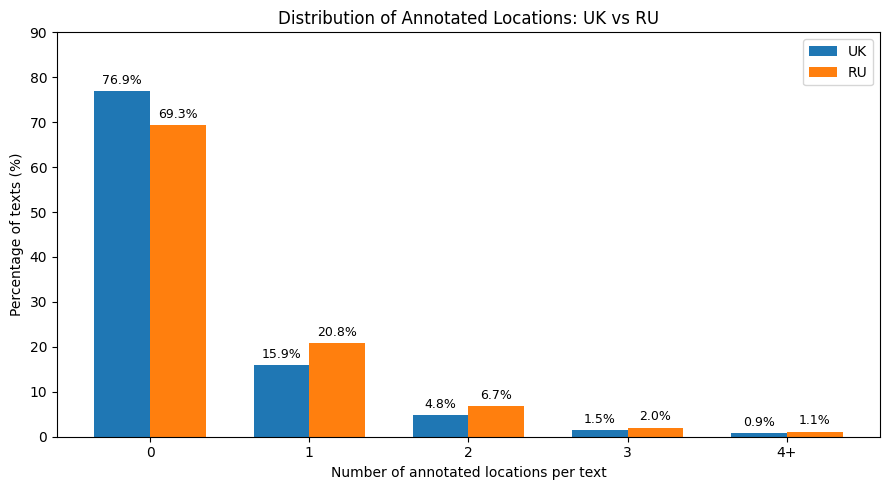

In [28]:
fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(5)
width = 0.35

for i, (label, df) in enumerate([("UK", uk_loc_dist), ("RU", ru_loc_dist)]):
    pct = df.groupby(df["n_locations"].clip(upper=4))["n_texts"].sum()
    pct = pct.reindex(range(5), fill_value=0) / df["n_texts"].sum() * 100
    bars = ax.bar(x + (i - 0.5) * width, pct, width, label=label)
    ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=9)

ax.set_xticks(x, ["0", "1", "2", "3", "4+"])
ax.set_xlabel("Number of annotated locations per text")
ax.set_ylabel("Percentage of texts (%)")
ax.set_title("Distribution of Annotated Locations: UK vs RU")
ax.legend()
ax.set_ylim(0, 90)

plt.tight_layout()
plt.show()

Most texts contain no annotated locations. Among texts with locations, single-location texts are the most common, while texts containing multiple locations are less frequent.

## Location Annotation Quality Checks

### Character Offset Validation

In [29]:
invalid_spans = 0
total_spans = 0
examples = []

for chunk in pd.read_csv(data_dir / "uk_geo_dataset.csv", usecols=["text", "loc_markers"], chunksize=100_000):
    for text, markers in zip(chunk["text"], chunk["loc_markers"]):
        if pd.isna(text) or pd.isna(markers):
            continue
        for start, end in ast.literal_eval(markers):
            total_spans += 1
            if not (0 <= start < end <= len(text)):
                invalid_spans += 1
                if len(examples) < 5:
                    examples.append((text, start, end))

print(f"Total spans: {total_spans:,}")
print(f"Invalid spans: {invalid_spans:,}")
print(f"Invalid rate: {invalid_spans / total_spans:.4%}" if total_spans else "No spans found")
print("Examples:", examples)

Total spans: 345,114
Invalid spans: 0
Invalid rate: 0.0000%
Examples: []


In [30]:
ru_invalid_spans = 0
ru_total_spans = 0
ru_examples = []

for chunk in pd.read_csv(data_dir / "ru_geo_dataset.csv", usecols=["text", "loc_markers"], chunksize=100_000):
    for text, markers in zip(chunk["text"], chunk["loc_markers"]):
        if pd.isna(text) or pd.isna(markers):
            continue
        for start, end in ast.literal_eval(markers):
            ru_total_spans += 1
            if not (0 <= start < end <= len(text)):
                ru_invalid_spans += 1
                if len(ru_examples) < 5:
                    ru_examples.append((text, start, end))

print(f"Total spans: {ru_total_spans:,}")
print(f"Invalid spans: {ru_invalid_spans:,}")
print(f"Invalid rate: {ru_invalid_spans / ru_total_spans:.4%}" if ru_total_spans else "No spans found")
print("Examples:", ru_examples)

Total spans: 3,708,173
Invalid spans: 0
Invalid rate: 0.0000%
Examples: []


All 4,053,287 examined location spans have valid character offsets and no overlapping location annotations were detected

### Overlapping Spans, Whitespace Boundaries and Span Lengths

We examine three additional properties of location annotations in the UK and ru datasets:

- **Overlapping spans**: Identify texts containing intersecting location annotations, which may cause ambiguity during BIO label conversion.

- **Whitespace boundaries**: Detect location spans that begin or end with whitespace, indicating potentially imprecise annotation boundaries.

- **Span lengths**: Analyze the character lengths of annotated locations to identify unusually long entities and potential annotation anomalies.

These checks help assess annotation consistency before tokenization and BIO label alignment.

In [31]:
def audit_location_spans(file_path):
    stats = Counter()
    lengths = Counter()
    examples = {"overlap": [], "whitespace": [], "longest": []}

    for chunk in pd.read_csv(file_path, usecols=["text", "loc_markers"], chunksize=100_000):
        for text, raw in zip(chunk["text"], chunk["loc_markers"]):
            if not isinstance(text, str) or pd.isna(raw):
                stats["missing"] += 1
                continue

            try:
                spans = ast.literal_eval(raw)
                if not isinstance(spans, (list, tuple)) or any(
                    not isinstance(s, (list, tuple)) or len(s) != 2
                    or not all(isinstance(v, int) for v in s)
                    or not 0 <= s[0] < s[1] <= len(text)
                    for s in spans
                ):
                    raise ValueError("Invalid span format")
            except (ValueError, SyntaxError, TypeError):
                stats["malformed"] += 1
                continue

            stats["texts"] += 1
            spans = sorted(spans)
            if any(spans[i][0] < spans[i - 1][1] for i in range(1, len(spans))):
                stats["overlap_texts"] += 1
                if len(examples["overlap"]) < 3:
                    examples["overlap"].append((text[:150], spans[:10]))

            for start, end in spans:
                location = text[start:end]
                stats["spans"] += 1
                lengths[len(location)] += 1

                if location[0].isspace() or location[-1].isspace():
                    stats["whitespace_spans"] += 1
                    if len(examples["whitespace"]) < 3:
                        examples["whitespace"].append(repr(location))

                if len(location) > 100:
                    stats["long_spans"] += 1
                    if len(examples["longest"]) < 3:
                        examples["longest"].append(location[:150])

    return stats, lengths, examples

In [32]:
uk_audit, uk_lengths, uk_examples = audit_location_spans(data_dir / "uk_geo_dataset.csv")
ru_audit, ru_lengths, ru_examples = audit_location_spans(data_dir / "ru_geo_dataset.csv")

summary = pd.DataFrame([uk_audit, ru_audit], index=["UK", "ru"]).fillna(0).astype(int)
display(summary.T)

,UK,ru
texts,1010000,8028840
spans,345114,3708173
whitespace_spans,206,13
long_spans,0,4


Whitespace boundary issues are rare: 206 spans in UK (0.060%) and 13 in ru (0.00035%). Additionally, only four ru spans exceed 100 characters, compared with none in UK.

Overall, the annotations appear structurally consistent. However, the whitespace cases and unusually long spans require manual inspection before deciding whether any preprocessing corrections are necessary.

### Manual Inspection of Suspicious Location Spans

In [35]:
print("UK whitespace examples:")
for example in uk_examples["whitespace"]:
    print(example)

print("\nru whitespace examples:")
for example in ru_examples["whitespace"]:
    print(example)

UK whitespace examples:
'Донецьку, '
'Луганській області "Золоте" та '
'Вознесенський жіночий '

ru whitespace examples:
'лидера, показанного в эфире телеканала «Россия '
'о '
'о перемирии в '


In [36]:
def inspect_whitespace_spans(file_path, max_examples=5, context=40):
    found = 0

    for chunk in pd.read_csv(file_path, usecols=["text", "loc_markers"], chunksize=100_000):
        for text, raw in zip(chunk["text"], chunk["loc_markers"]):
            if not isinstance(text, str) or pd.isna(raw):
                continue

            for start, end in ast.literal_eval(raw):
                location = text[start:end]
                if location and (location[0].isspace() or location[-1].isspace()):
                    left = text[max(0, start - context):start]
                    right = text[end:end + context]

                    print(f"Text: {left}[{location}]{right}")
                    print(f"Location: {location!r}")
                    print(f"Offsets: ({start}, {end})\n")

                    found += 1
                    if found >= max_examples:
                        return

UK:

In [37]:
inspect_whitespace_spans(data_dir / "uk_geo_dataset.csv", max_examples=5)

Text: ці беруть участь в атаках на аеропорт в [Донецьку, ]- штаб АТО Бойовики продовжують атакуват
Location: 'Донецьку, '
Offsets: (63, 73)

Text: трольних пунктів в'їзду-виїзду (КПВВ) у [Луганській області "Золоте" та ]"Щастя" на 10 листопада.
Location: 'Луганській області "Золоте" та '
Offsets: (69, 100)

Text: А до того на цьому місці стояв [Вознесенський жіночий ]монастир, в якому ігуменею була Марина, 
Location: 'Вознесенський жіночий '
Offsets: (31, 53)

Text: і 15 квітня оголошена евакуація острова [Сіте, на якому ]розташований охоплений вогнем собор Пари
Location: 'Сіте, на якому '
Offsets: (55, 70)

Text: Нагадаємо, у ніч проти 30 жовтня у [Мурманській області Росії сталася ]аварія, унаслідок якої плавучий док зато
Location: 'Мурманській області Росії сталася '
Offsets: (35, 69)



ru:

In [38]:
inspect_whitespace_spans(data_dir / "ru_geo_dataset.csv", max_examples=5)

Text:  этом говорится в заявлении российского [лидера, показанного в эфире телеканала «Россия ]1».
Location: 'лидера, показанного в эфире телеканала «Россия '
Offsets: (42, 89)

Text: овано совместное заявление России и США [о ]прекращении огня в Арабской Республике.
Location: 'о '
Offsets: (102, 104)

Text:  между Москвой и Вашингтоном соглашение [о перемирии в ]Сирии.
Location: 'о перемирии в '
Offsets: (93, 107)

Text: от же день в Киеве произошли беспорядки [в центре ]города.
Location: 'в центре '
Offsets: (44, 53)

Text:  лотерею, призом в которой будет ужин с [главой Минкульта ]Владимиром Мединским, сообщает РИА Новос
Location: 'главой Минкульта '
Offsets: (139, 156)



Some contain extra spaces or punctuation, while others mark text that is not a location.

In [41]:
import random
def sample_location_spans(file_path, n=100, seed=42):
    rng = random.Random(seed)
    sample = []
    seen = 0

    for chunk in pd.read_csv(file_path, usecols=["text", "loc_markers"], chunksize=100_000):
        for text, raw in zip(chunk["text"], chunk["loc_markers"]):
            if not isinstance(text, str) or pd.isna(raw):
                continue

            for start, end in ast.literal_eval(raw):
                seen += 1
                record = {
                    "text": text,
                    "start": start,
                    "end": end,
                    "location": text[start:end]
                }

                if len(sample) < n:
                    sample.append(record)
                else:
                    j = rng.randrange(seen)
                    if j < n:
                        sample[j] = record

    return pd.DataFrame(sample)

In [42]:
uk_sample = sample_location_spans(data_dir / "uk_geo_dataset.csv")
ru_sample = sample_location_spans(data_dir / "ru_geo_dataset.csv")

print(f"UK: {len(uk_sample)} annotations")
print(f"ru: {len(ru_sample)} annotations")

UK: 100 annotations
ru: 100 annotations


In [44]:
def prepare_review(df, context=50):
    review = df.copy()
    review["context"] = review.apply(
        lambda r: r["text"][max(0, r["start"] - context):r["start"]]
        + " [" + r["location"] + "] "
        + r["text"][r["end"]:r["end"] + context],
        axis=1
    )
    review["review"] = ""
    return review[["location", "context", "review"]]

uk_review = prepare_review(uk_sample)
ru_review = prepare_review(ru_sample)

pd.set_option("display.max_colwidth", None)
display(uk_review.head(10))

,location,context,review
0,Широкиного,На захист [Широкиного] незабаром прибуде один з найкращих українських пі,
1,Харків,травмами привезли до реанімаційного відділення в [Харків] .,
2,-Франківська,"Власник ""жужика"" з Івано [-Франківська] перетворив свій ""Запорожець"" на справжній шедевр.",
3,Новоолексіївка,"Інцидент трапився пізно ввечері 29 вересня у смт [Новоолексіївка] , але затримати зловмисників вдалося лише зараз.",
4,Англія,"[Англія] , Франція, Австрія, Німеччина, Іспанія знову вводя",
5,Китай,"м, у липні лідерство в рейтингу традиційно зберіг [Китай] із показником 81,241 млн т (зростання на 7,2% про",
6,Німеччини,"Ми запросили наших колег із відповідних органів [Німеччини] , Нідерландів, Великої Британії, Кіпру, Швейцарії,",
7,Чернівці,"ром, 20 травня, з тої-таки європейської столиці в [Чернівці] надійшла відповідь.",
8,України,"ин було встановлено, що затриманий є громадянином [України] , жителем Жмеринки (Вінницька обл.) і перебуває у",
9,Донбасі,Порошенко також розповів Барн'є про ситуацію на [Донбасі] і невиконання Росією Мінських домовленостей.,


In [49]:
pd.set_option("display.max_colwidth", None)

print("UK — additional examples")
display(uk_review.iloc[10:20][["location", "context"]])

print("ru — examples")
display(ru_review.iloc[:10][["location", "context"]])

UK — additional examples


,location,context
10,моста Патона,У процесі реконструкції з [моста Патона] приберуть радянську символіку - зірки і вінки з к
11,Ісландія,"пі Ліги А, її суперниками стали Бельгія, Данія та [Ісландія] ."
12,Полтавській області,"У [Полтавській області] до пошуків Романа Скрипника, який утримував у зар"
13,Туреччини,"нфлікт визрівав навколо більшої лояльності США до [Туреччини] як потужнішої держави у військовій сфері, підрощу"
14,Чехословаччині,"Однак протести в Угорщині 1956 року, [Чехословаччині] 1968-го й Польщі 1980-го стали початком його неми"
15,Олімпіаді,"заявив після 4 перемог і одного другого місця на [Олімпіаді] у Лондоні, що йде з великого спорту."
16,Німеччини,"ої операції ми проводили консультації з канцлером [Німеччини] "", - сказав Макрон."
17,КНР,"суботи, 28 березня, тимчасово заборонено в'їзд до [КНР] ."
18,Торжок Тверської області,"рших секунд приїзду сюди, в ІК-4 (колонія в місті [Торжок Тверської області] – ред.)."
19,Британії,"Для [Британії] в “брекзиті” немає позитивних сторін, – заявив Гу"


ru — examples


,location,context
0,Российская,"[Российская] сторона предоставила нидерландской комиссии, кото"
1,Чите,В [Чите] полностью сгорело здание складов и сервисного цен
2,США,"Однако две недели назад власти [США] объявили, что не намерены передавать кому-либо ба"
3,России,"те организации, являются администрация президента [России] и правительство Москвы, а председателем правления"
4,Турцией,"тия на границе говорят о том, что соглашению ЕС с [Турцией] , по которому она обязывается обеспечивать безопас"
5,Францию,"имости Европы, сменив прежде бессменного лидера — [Францию] ."
6,Подмосковья,годняя елка страны была срублена в Рузском районе [Подмосковья] .
7,Чечне,"м для участников контртеррористической операции в [Чечне] , - по 650-680 рублей в сутки за непосредственное"
8,Лахор,", произошедшего в 2006 году в пакистанском городе [Лахор] ."
9,Ирана,"и на фоне нефтяного эмбарго Евросоюза в отношении [Ирана] , которое вступит в силу 1 июля этого года."


In [50]:
pd.set_option("display.max_colwidth", None)

print("UK — additional examples")
display(uk_review.iloc[20:30][["location", "context"]])

print("ru — examples")
display(ru_review.iloc[10:20][["location", "context"]])

UK — additional examples


,location,context
20,Росія,А [Росія] користає з поганого економічного стану України в
21,України,"е знає, коли його клієнт має намір повернутися до [України] і чи піде після цього на допит."
22,Європи,ґрунт для якої має цілий потік негативних новин з [Європи] .
23,Лізі націй,що Льова зі збірної Німеччини після від Іспанії в [Лізі націй] .
24,Запорізької області,"1 липня поверталася з сином додому від родичів із [Запорізької області] потягом ""Маріуполь-Київ"", стала жертвою нападника"
25,Волинській області,"Згодом працював в УБОЗ УМВС України у [Волинській області] , у відділі карного розшуку Луцького міськвідділу"
26,Північному потоці-1,"повному завантаженні трубопроводів, то на жаль, в [Північному потоці-1] , вони нижчі, ніж через українську, словацьку, чес"
27,"Донецької, Запорізької та Харківської областей","ужб РФ для підготовки низки терактів на території [Донецької, Запорізької та Харківської областей] ."
28,Донбасі,"Кремль продовжує проводити стратегію ескалації на [Донбасі] ""."
29,Україні,"що високі тарифи на житлово-комунальні послуги в [Україні] не страшні для населення, бо кожен, хто її потреб"


ru — examples


,location,context
10,Европейский союз,"10 февраля стало известно, что [Европейский союз] собирается выделить Украине транш финансовой помо"
11,Куюмба,"Восточная Мессояха, Юрубчено-Тохомское, Русское, [Куюмба] , Тагул."
12,Кипр,В топ-5 стран также вошли [Кипр] и Испания.
13,России,приглашения на Игры в Пхенчхане 15 представителям [России] .
14,Канаде,наиболее дорогих и престижных учебных заведений в [Канаде] .
15,Ламишино,Истринского водохранилища у подмосковной деревни [Ламишино] в понедельник пригрозили натравить собак на крими
16,Афганистана,"показ атак боевиков связан с желанием руководства [Афганистана] ""скрыть свои ошибки""."
17,Ле Гау,", как собирался, поэтому его прах будет развеян в [Ле Гау] на Средиземном море, «где ему было лучше всего»,"
18,Мак-Мердо,"ериканский антарктический исследовательский центр [Мак-Мердо] образца льда высотой до метра, откуда его транспо"
19,Украина,"Позднее Россия и [Украина] договорились о поставках электроэнергии, обеспечи"


In [51]:
pd.set_option("display.max_colwidth", None)

print("UK — additional examples")
display(uk_review.iloc[30:40][["location", "context"]])

print("ru — examples")
display(ru_review.iloc[20:30][["location", "context"]])

UK — additional examples


,location,context
30,Україні,"про нібито порушення прав угорців, які мешкають в [Україні] , через положення закону, яким визначено, що мовою"
31,Україна,"«В переговорному процесі щодо асоціації з ЄС [Україна] відіграла певну роль такого криголаму, першопрохі"
32,Харківським регіоном,ином тут розвиваються відносини - змістовно - між [Харківським регіоном] і Словаччиною.
33,Кремлем,", але надії на справедливе рішення заангажованого [Кремлем] суду немає."
34,Київ,ного електропотяга «Інтерсіті» маршрутом «Черкаси- [Київ] ».
35,Україні,"Посол Німеччини в [Україні] Ганс-Юрґен Гаймзьот заявив, що німецькі вболіваль"
36,Києва,Національна поліція [Києва] забезпечила доставку громадянина Грузії в органи
37,Шевченківських вечорах,"м, тож про них заговорило все місто. Через рік на [Шевченківських вечорах] Катерина відважилась виконати солоспіви: «Нащо ме"
38,Польщі,"Завершилися переговори віце-прем'єрів України та [Польщі] щодо закону про заборону ""бандеризму""журнал «Укра"
39,Києво-,У [Києво-] Святошинському районі затримали небезпечну банду в


ru — examples


,location,context
20,Джорджии,"рождение"" (New Birth Missionary Baptist Church) в [Джорджии] считается одной из крупнейших афроамериканских ре"
21,Красной площади,"В воскресенье, 7 ноября, на [Красной площади] прошло шествие, посвященное 63-й годовщине истори"
22,Франции,"из «Спартака» Робсон выступал за клубы из Японии, [Франции] , Бразилии и Китая."
23,Южно-Сахалинска,Из [Южно-Сахалинска] пограничным самолетом они были направлены на лече
24,Северо-Западе,"дования в отношении таможенных злоупотреблений на [Северо-Западе] , проводились обыски у главы ФТС Андрея Бельянинов"
25,Украины,"и оппозиционных фракций - Коммунистической партии [Украины] , Социалистической партии, ""Нашей Украины"" и Блока"
26,Донбассу,"ередь, ввел в действие решение Совбеза Украины по [Донбассу] ."
27,Храброво,Реконструкция аэропорта [Храброво] проводится в рамках федеральной целевой программы
28,Швеции,"числе ИГ», — заявил начальник Управления полиции [Швеции] Йонас Хайзинг."
29,Сирии,Вооруженный конфликт в [Сирии] продолжается с 2011 года.


We visually inspected 70 randomly sampled location annotations (40 UK and 30 ru).

Most annotations appeared correct, but several issues were identified:

- **Incorrect boundaries**: -Франківська instead of Івано-Франківська; Києво- instead of Києво-Святошинському.

- **Non-location entities**: Олімпіаді, Лізі націй, Шевченківських вечорах.

- **Multiple locations in one span**: Донецької, Запорізької та Харківської областей.

- **Ambiguous labels**: Кремлем (referring to the government), Европейский союз (an organization rather than a geographical location).

These examples show that structurally valid character offsets do not guarantee correct annotations.

No automatic corrections were applied.

In [33]:
def length_quantiles(counts):
    values = np.array(sorted(counts))
    cumulative = np.cumsum([counts[v] for v in values])
    return [int(values[np.searchsorted(cumulative, cumulative[-1] * q, side="left")])
            for q in [0.5, 0.95, 0.99, 1.0]]

length_summary = pd.DataFrame(
    [length_quantiles(uk_lengths), length_quantiles(ru_lengths)],
    index=["UK", "ru"],
    columns=["Median", "P95", "P99", "Max"]
)
display(length_summary)

,Median,P95,P99,Max
UK,7,20,28,82
ru,7,18,25,171


###  Most Frequent Locations

In [45]:
def count_locations(file_path):
    counts = Counter()

    for chunk in pd.read_csv(file_path, usecols=["text", "loc_markers"], chunksize=100_000):
        for text, raw in zip(chunk["text"], chunk["loc_markers"]):
            if not isinstance(text, str) or pd.isna(raw):
                continue
            for start, end in ast.literal_eval(raw):
                counts[text[start:end]] += 1

    return counts

uk_locations = count_locations(data_dir / "uk_geo_dataset.csv")
ru_locations = count_locations(data_dir / "ru_geo_dataset.csv")

print("UK — top 20:")
display(pd.DataFrame(uk_locations.most_common(20), columns=["location", "count"]))

print("ru — top 20:")
display(pd.DataFrame(ru_locations.most_common(20), columns=["location", "count"]))

UK — top 20:


,location,count
0,України,24432
1,Україні,16849
2,США,8862
3,Росії,7704
4,Україна,7425
5,Києві,6541
6,Києва,4061
7,Україну,4036
8,Криму,3510
9,РФ,3349


ru — top 20:


,location,count
0,России,315084
1,США,212502
2,РФ,99327
3,Украины,86016
4,Москве,65507
5,Москвы,60854
6,Россия,41469
7,Великобритании,32841
8,Германии,26717
9,Франции,26041


The most frequent locations include countries, cities and regions.

Different grammatical forms of the same location are counted separately (e.g., "Україна", "України", "Україні"). This increases the number of unique location strings.

### Multiword Locations

In [46]:
def location_word_stats(counts):
    total = sum(counts.values())
    multiword = sum(n for loc, n in counts.items() if len(loc.split()) > 1)
    return {
        "total_spans": total,
        "unique_strings": len(counts),
        "multiword_pct": round(100 * multiword / total, 2)
    }

display(pd.DataFrame({
    "UK": location_word_stats(uk_locations),
    "ru": location_word_stats(ru_locations)
}).T)

,total_spans,unique_strings,multiword_pct
UK,345114.0,45430.0,15.39
ru,3708173.0,132589.0,11.86


Most annotated locations are single-word expressions.

## Duplicate Texts

In [47]:
def check_chunk_duplicates(file_path):
    total = 0
    duplicates = 0

    for chunk in pd.read_csv(file_path, usecols=["text"], chunksize=100_000):
        total += len(chunk)
        duplicates += chunk["text"].duplicated().sum()

    return {
        "total_rows": total,
        "duplicates_within_chunks": duplicates,
        "duplicates_pct_lower_bound": round(100 * duplicates / total, 2)
    }

display(pd.DataFrame({
    "UK": check_chunk_duplicates(data_dir / "uk_geo_dataset.csv"),
    "ru": check_chunk_duplicates(data_dir / "ru_geo_dataset.csv")
}).T)

,total_rows,duplicates_within_chunks,duplicates_pct_lower_bound
UK,1010000.0,237.0,0.02
ru,8028840.0,360259.0,4.49


These are lower-bound estimates because duplicates across different chunks were not counted.

Duplicates may cause data leakage if identical texts appear in both training and validation sets. A complete duplicate check is needed before splitting the data.

## Document Grouping

In [48]:
doc_counts = Counter()

for chunk in pd.read_csv(data_dir / "ru_geo_dataset.csv", usecols=["doc_id"], chunksize=100_000):
    doc_counts.update(chunk["doc_id"].dropna().value_counts().to_dict())

doc_sizes = pd.Series(list(doc_counts.values()))

print("Unique documents:", len(doc_counts))
print("Missing doc_id rows:", 8_028_840 - doc_sizes.sum())
display(doc_sizes.describe(percentiles=[0.5, 0.9, 0.95, 0.99]).to_frame("texts_per_document"))

Unique documents: 739190
Missing doc_id rows: 0


,texts_per_document
count,739190.000000
mean,10.861673
std,4.362213
min,1.000000
50%,10.000000
90%,16.000000
95%,18.000000
99%,23.000000
max,686.000000


The ru dataset contains 739,190 unique documents, with an average of 10.86 texts per document.

All rows have a `doc_id`. Multiple texts from the same document may share context and information.

Document-level grouping should be considered during validation to reduce data leakage.

# Metrics analysis

## Target Metric

The proposed metric is `normalized set-based micro F1`

For each text, true and predicted locations are normalized and converted into sets. TP, FP and FN are then aggregated across all texts.

$$
F1 = \frac{2TP}{2TP + FP + FN}
$$

Normalization includes lowercasing and removing punctuation, digits, single-character words and extra whitespace.

**This is a standard micro F1 formula with competition-specific matching rules.**


### Its pros:
- Bounded between 0 and 1, making results easy to compare.

- Balances precision and recall without being inflated by true negatives.

- Measures overall extraction quality across the entire dataset.

- Weights each counted location equally, reflecting the dataset's actual entity distribution.

- Kaggle normalization tolerates capitalization and punctuation differences.

### Its cons:

- Not differentiable, so it cannot be used directly as a training loss.

- Frequent locations and larger language groups can dominate the score, hiding poor performance on rare entities.

- Does not evaluate exact entity boundaries or character offsets.

- Gives no partial credit for incomplete location names.

- Ignores repeated occurrences of the same location within one text.



### Potential edge cases:

- Київ vs. київ! - match after normalization.

- Київ vs. Києві - mismatch because lemmatization is not applied.

- Івано-Франківськ vs. Франківськ - no partial credit.

- Duplicate locations within one text are counted only once.

## Complementary metrics

Alongside Kaggle Micro F1, we can evaluate:

- Entity-level F1 (seqeval): checks whether complete entities and their BIO boundaries are correctly predicted.

- Precision and Recall: distinguish false positives from missed locations.

- F1 by language (UK / ru): reveals performance differences hidden by global micro averaging.

## Alternative target metric

Macro F1 across language groups gives equal weight to UK and ru:

$$
F1_{\text{macro-lang}} = \frac{F1_{\text{UK}} + F1_{\text{ru}}}{2}
$$

Unlike global Micro F1, it highlights weaker performance on an underrepresented language. However, it does not reflect the actual distribution of location instances and is not the official competition metric.